# Phân cụm khách hàng bằng RFM + K-Means (Online Retail II)

**Mục tiêu:** chia khách hàng thành các nhóm có hành vi mua hàng tương đồng để doanh nghiệp biết nên chăm sóc, giữ chân hay kích hoạt lại nhóm nào. Kết quả sẽ được đưa vào Power BI.

**Quy trình**

| # | Bước | Câu hỏi cần trả lời |
|---|---|---|
| 1 | Đọc dữ liệu | Dữ liệu có gì, thiếu gì? |
| 2 | Làm sạch | Dòng nào không phản ánh hành vi mua thật? |
| 3 | Tính RFM | Mỗi khách hàng "mua gần đây / thường xuyên / nhiều" đến đâu? |
| 4 | Biến đổi + chuẩn hóa | Dữ liệu đã phù hợp với K-Means chưa? |
| 5 | Chọn k | Nên chia thành bao nhiêu cụm? |
| 6 | Huấn luyện + kiểm tra | Cụm có ổn định, tách biệt không? |
| 7 | Profile + đặt tên | Mỗi cụm là ai, đóng góp bao nhiêu doanh thu? |
| 8 | Xuất dữ liệu cho Power BI | Bảng nào cần đưa sang Power BI để làm data modeling và dashboard? |

> **Lưu ý về phần "Nhận xét":** các nhận xét dưới mỗi cell dựa trên lần chạy với `random_state=42` trên đúng file `online_retail_II.csv`. Nếu bạn đổi dữ liệu hoặc tham số, hãy đọc lại và cập nhật các con số.

## 0. Thiết lập môi trường

**Vì sao làm vậy?**
- Gom toàn bộ `import` và hằng số vào một chỗ để dễ tái lập (reproducibility).
- `RANDOM_STATE = 42`: K-Means khởi tạo tâm cụm ngẫu nhiên, cố định seed để kết quả giống nhau mỗi lần chạy.
- Tạo sẵn các thư mục đầu ra để các cell cuối không bị lỗi thiếu thư mục.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

RAW_PATH = "online_retail_II.csv"
for d in ["data/clean", "data/processed", "reports", "models", "powerbi"]:
    os.makedirs(d, exist_ok=True)

**Nhận xét output:** cell này không in gì. Nếu không có lỗi `ModuleNotFoundError` nghĩa là môi trường đã đủ thư viện (pandas, scikit-learn, matplotlib, seaborn, joblib).

## 1. Đọc dữ liệu

**Vì sao làm vậy?**
- Dataset là dữ liệu giao dịch, mỗi dòng là một mặt hàng trong một hóa đơn. Mục tiêu phân cụm là **khách hàng**, nên sau này phải gom từ dòng giao dịch lên cấp khách hàng.
- `parse_dates=["InvoiceDate"]` để tính khoảng cách ngày (Recency) mà không phải ép kiểu sau.
- Ép `Invoice` và `StockCode` về chuỗi, vì mã hóa đơn hủy bắt đầu bằng chữ "C" và nhiều mã sản phẩm có chữ (vd `79323P`). Nếu để pandas tự suy luận kiểu, hai cột này có thể bị trộn kiểu.
- Kiểm tra số lượng null ngay từ đầu để biết cột nào cần xử lý.

In [2]:
# Cột chữ lặp lại nhiều -> category để tiết kiệm RAM (file có >1 triệu dòng)
DTYPES = {"Invoice": "str", "StockCode": "str", "Description": "category", "Country": "category"}
try:
    df = pd.read_csv(RAW_PATH, encoding="utf-8", parse_dates=["InvoiceDate"], dtype=DTYPES)
except UnicodeDecodeError:
    df = pd.read_csv(RAW_PATH, encoding="latin1", parse_dates=["InvoiceDate"], dtype=DTYPES)
print(df.shape)
display(df.head())
display(df.isna().sum().to_frame("null"))

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


,null
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


**Nhận xét output**
- Kích thước **(1.067.371 dòng × 8 cột)**: đủ lớn để K-Means chạy ổn định, nhưng đây là số dòng giao dịch, chưa phải số khách hàng.
- Hai cột có giá trị thiếu:
  - `Customer ID`: **243.007 dòng (~22,8%)** bị thiếu. Đây là vấn đề lớn nhất, vì không có ID thì không biết giao dịch thuộc khách nào, nên không thể đưa vào RFM.
  - `Description`: 4.382 dòng thiếu. Không ảnh hưởng RFM vì ta không dùng mô tả sản phẩm làm feature.
- Các cột `Quantity`, `Price`, `InvoiceDate` không có null. Điều này chưa có nghĩa là hợp lệ, ta sẽ kiểm tra giá trị âm/0 ở bước sau.

## 2. Làm sạch dữ liệu

**Vì sao phải làm sạch trước khi tính RFM?** RFM chỉ có ý nghĩa nếu các giao dịch đại diện cho **hành vi mua thật của một khách hàng xác định**. Dữ liệu bẩn sẽ làm sai cả ba chỉ số và kéo lệch tâm cụm K-Means (K-Means rất nhạy với outlier vì dựa trên khoảng cách Euclid).

Các bước và lý do:

| Bước | Lý do |
|---|---|
| Bỏ dòng thiếu `Customer ID` | Không gán được cho khách hàng nào |
| Bỏ `Quantity <= 0` hoặc `Price <= 0` | Điều chỉnh kho, hàng tặng, lỗi nhập liệu. Bước này cũng loại toàn bộ hóa đơn hủy (mã bắt đầu bằng "C"), vì các dòng hủy luôn có `Quantity` âm |
| Bỏ dòng trùng lặp | Tránh đếm đôi giá trị |

In [3]:
log = []
def step(name, before, after):
    log.append({"step": name, "rows_before": before, "rows_after": after, "removed": before - after})

n0 = len(df)
data = df
del df  # giải phóng bảng gốc để tiết kiệm RAM

# 1. Thiếu Customer ID
b = len(data); data = data.dropna(subset=["Customer ID"]); step("Thiếu Customer ID", b, len(data))
data["Customer ID"] = data["Customer ID"].astype(int)

# 2. Quantity / Price không hợp lệ (gồm cả hóa đơn hủy mã C, có Quantity âm)
b = len(data); data = data[(data["Quantity"] > 0) & (data["Price"] > 0)]; step("Quantity<=0 hoặc Price<=0 (gồm hóa đơn hủy)", b, len(data))

# 3. Trùng lặp
b = len(data); data = data.drop_duplicates(); step("Dòng trùng lặp", b, len(data))

data["TotalPrice"] = data["Quantity"] * data["Price"]
data = data.reset_index(drop=True)

cleaning_log = pd.DataFrame(log)
display(cleaning_log)
print(f"Giữ lại {len(data):,}/{n0:,} dòng ({len(data)/n0:.1%}); {data['Customer ID'].nunique():,} khách hàng")
print("Khoảng thời gian:", data["InvoiceDate"].min(), "->", data["InvoiceDate"].max())

,step,rows_before,rows_after,removed
0,Thiếu Customer ID,1067371,824364,243007
1,Quantity<=0 hoặc Price<=0 (gồm hóa đơn hủy),824364,805549,18815
2,Dòng trùng lặp,805549,779425,26124


Giữ lại 779,425/1,067,371 dòng (73.0%); 5,878 khách hàng
Khoảng thời gian: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


**Nhận xét output**
- Bảng log cho thấy **thiếu `Customer ID` là nguồn mất dữ liệu lớn nhất (243.007 dòng)**, sau đó là dòng trùng lặp (26.124) và dòng có số lượng/giá không hợp lệ (18.815 dòng). Trong 18.815 dòng này, **18.744 dòng là hóa đơn hủy** (mã "C", `Quantity` âm), chỉ 71 dòng còn lại là giá/số lượng không hợp lệ khác.
- Còn **779.425 / 1.067.371 dòng (73,0%)**, tương ứng **5.878 khách hàng** trong khoảng **01/12/2009 đến 09/12/2011** (hai năm). Mất ~27% dòng nghe nhiều, nhưng phần lớn là các dòng *không thể* dùng cho phân tích khách hàng chứ không phải mất thông tin hành vi.
- Giới hạn cần nhớ: 22,8% giao dịch không có ID (có thể là khách vãng lai) nên kết quả chỉ mô tả **khách hàng đã định danh**, không phải toàn bộ doanh thu.
- **Ta không lọc `StockCode` không phải sản phẩm** (POST, M, C2...). Các dòng này vẫn nằm trong dữ liệu; mức ảnh hưởng nhỏ và được phân tích ở nhận xét kế tiếp.
- Ta chỉ loại **dòng hủy** (mã "C"), dòng bán gốc của đơn bị hủy vẫn còn.

In [4]:
# Quan sát giá trị cực đoan (chỉ loại khi chắc chắn là lỗi nhập liệu)
print(data[["Quantity", "Price", "TotalPrice"]].describe(percentiles=[.5, .99, .999]).round(2))
display(data.nlargest(5, "TotalPrice")[["Invoice", "StockCode", "Description", "Quantity", "Price", "TotalPrice", "Customer ID"]])

        Quantity      Price  TotalPrice
count  779425.00  779425.00   779425.00
mean       13.49       3.22       22.29
std       145.86      29.68      227.43
min         1.00       0.00        0.00
50%         6.00       1.95       12.48
99%       144.00      14.95      203.52
99.9%     576.00      49.95      864.00
max     80995.00   10953.50   168469.60


,Invoice,StockCode,Description,Quantity,Price,TotalPrice,Customer ID
778958,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446
423253,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,12346
540311,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.0,15098
333149,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15818.4,15838
96834,502263,M,Manual,1,10953.50,10953.5,12918


**Vì sao làm vậy?** Sau khi làm sạch cơ học, cần nhìn phân phối để phát hiện outlier còn sót. K-Means bị ảnh hưởng nặng bởi vài điểm cực lớn, nên phải phân biệt: giá trị lớn **có thật** (khách sỉ) hay **lỗi/đảo chiều** (đơn bị hủy).

**Nhận xét output**
- Trung vị `TotalPrice` mỗi dòng chỉ ~12,5 nhưng trung bình ~22 và max 168.470: phân phối **lệch phải mạnh**, hầu hết dòng là đơn nhỏ.
- 99,9% dòng có `Quantity` ≤ 576, trong khi max là 80.995. `Price` max là 10.953,5, cao bất thường so với 99,9% dòng ≤ 49,95.
- **Top 2 dòng là đơn đã bị hủy:** đơn `581483` (khách 16446, 80.995 cái, 168.470) và `541431` (khách 12346, 74.215 cái, 77.183) đã **bị hủy toàn bộ** ngay sau đó (hóa đơn `C581484` và `C541433`). Vì ta chỉ loại dòng hủy chứ không loại dòng bán gốc, hai khách này bị tính chi tiêu "ảo" lớn.
- **Dòng thứ 5 là phí thủ công:** hóa đơn `502263` có `StockCode = M` ("Manual"), giá 10.953,5, khách 12918. Đây không phải hàng hóa. Vì ta không lọc `StockCode` phi sản phẩm nên dòng này vẫn nằm trong dữ liệu.
- Mức ảnh hưởng tổng thể của các mã phi sản phẩm (POST, M, C2, ADJUST, BANK CHARGES...) là nhỏ: ~2.846 dòng (**0,37%** số dòng, khoảng **1,8%** tổng giá trị), nhưng có **375 hóa đơn chỉ gồm các dòng như vậy**, nên chúng làm Frequency tăng nhẹ ở một số khách. Chấp nhận được cho bài toán phân khúc, nhưng nên ghi vào hạn chế.
- Các dòng lớn còn lại trông **thật** (vd `PICNIC BASKET WICKER` giá 649,5 × 60 = 38.970, hoặc đơn sỉ vài nghìn cái đèn giá vài đồng), nên giữ lại.

## 3. Tính RFM

**Vì sao RFM?** Thay vì dùng hàng triệu dòng giao dịch, ta tóm tắt mỗi khách hàng bằng 3 con số có ý nghĩa kinh doanh:
- **Recency (R):** số ngày từ lần mua gần nhất đến ngày tham chiếu. *Nhỏ hơn = tốt hơn* (khách còn "nóng").
- **Frequency (F):** số hóa đơn khác nhau. Dùng `nunique` của `Invoice`, không đếm số dòng, vì một đơn nhiều mặt hàng chỉ là một lần mua.
- **Monetary (M):** tổng chi tiêu.

`snapshot_date` = ngày giao dịch cuối cùng + 1 ngày: mô phỏng "hôm nay" là ngay sau dữ liệu kết thúc, đảm bảo Recency tối thiểu là 1 (không có giá trị 0).
`Country` lấy theo giá trị xuất hiện nhiều nhất của khách, để dùng làm bộ lọc trong Power BI.

In [5]:
snapshot_date = data["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date)

rfm = data.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("TotalPrice", "sum"),
    Country=("Country", lambda x: x.mode().iat[0]),
).reset_index()

display(rfm.describe().round(2))
assert rfm[["Recency", "Frequency", "Monetary"]].gt(0).all().all()

Snapshot date: 2011-12-10 12:50:00


,Customer ID,Recency,Frequency,Monetary
count,5878.00,5878.00,5878.00,5878.00
mean,15315.31,201.33,6.29,2955.90
std,1715.57,209.34,13.01,14440.85
min,12346.00,1.00,1.00,2.95
25%,13833.25,26.00,1.00,342.28
50%,15314.50,96.00,3.00,867.74
75%,16797.75,380.00,7.00,2248.30
max,18287.00,739.00,398.00,580987.04


**Nhận xét output**
- Có **5.878 khách hàng**, mỗi người một dòng. `assert` qua nghĩa là cả R, F, M đều > 0 (không có lỗi logic).
- **Recency:** trung bình ~201 ngày, trung vị 96 ngày, max ~739 ngày (~2 năm). Trung bình lớn hơn trung vị nhiều: có một nhóm lớn khách đã lâu không quay lại.
- **Frequency:** trung vị chỉ **3 đơn**, khoảng **28% khách chỉ mua 1 lần**, nhưng max là **398 đơn**. Rất lệch phải.
- **Monetary:** trung vị ~868 nhưng trung bình ~2.956 và max ~580.987. Độ lệch chuẩn (~14.441) gấp ~5 lần trung bình, cho thấy một số ít khách (có thể là khách sỉ) chi tiêu vượt xa số đông.
- Hệ quả: **F và M không thể đưa thẳng vào K-Means**, phải biến đổi ở bước 4.

Text(0.5, 1.0, 'Monetary Distribution')

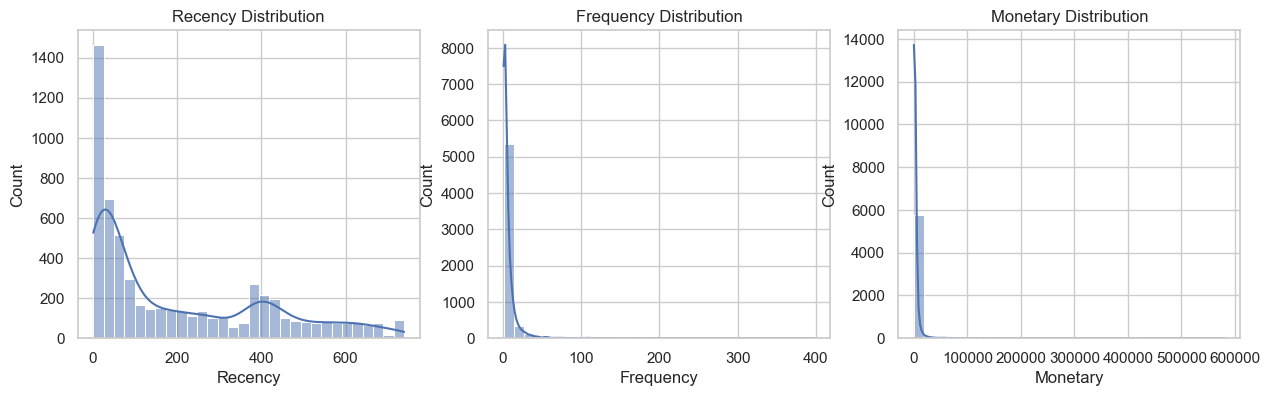

In [6]:
#phân phối các biến RFM
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(rfm["Recency"], bins=30, ax=axes[0], kde=True)
axes[0].set_title("Recency Distribution")
sns.histplot(rfm["Frequency"], bins=30, ax=axes[1], kde=True)
axes[1].set_title("Frequency Distribution")
sns.histplot(rfm["Monetary"], bins=30, ax=axes[2], kde=True)
axes[2].set_title("Monetary Distribution")      

In [7]:
df_customers = rfm[["Recency", "Frequency", "Monetary"]].copy()

In [8]:
from scipy import stats

def analyze_skewness(x):
    fig, ax = plt.subplots(2, 2, figsize=(5, 5))

    sns.distplot(df_customers[x], ax=ax[0, 0])
    sns.distplot(np.log(df_customers[x]), ax=ax[0, 1])
    sns.distplot(np.sqrt(df_customers[x]), ax=ax[1, 0])
    sns.distplot(stats.boxcox(df_customers[x])[0], ax=ax[1, 1])

    plt.tight_layout()
    plt.show()

    print(df_customers[x].skew().round(2))
    print("log", np.log(df_customers[x]).skew().round(2))
    print("sqrt", np.sqrt(df_customers[x]).skew().round(2))
    print("boxcox", pd.Series(stats.boxcox(df_customers[x])[0]).skew().round(2))

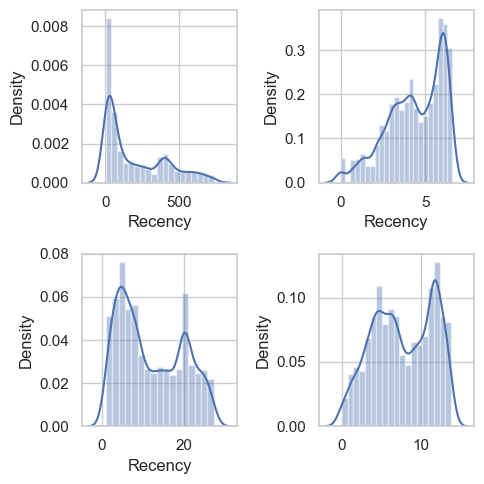

0.89
log -0.62
sqrt 0.35
boxcox -0.13


In [9]:
analyze_skewness('Recency')

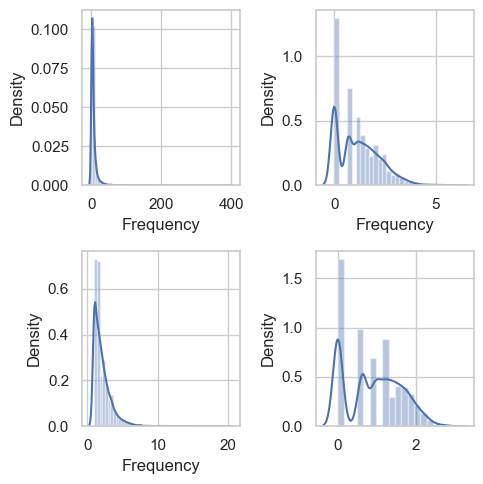

12.64
log 0.61
sqrt 3.08
boxcox 0.1


In [10]:
analyze_skewness('Frequency')

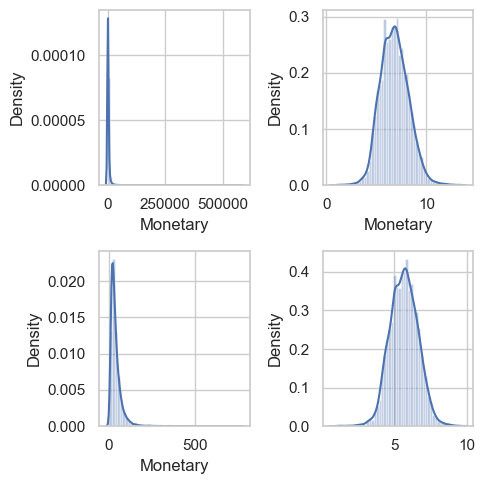

25.07
log 0.25
sqrt 6.03
boxcox -0.01


In [11]:
analyze_skewness('Monetary')

In [12]:
df_customers_transform = rfm[["Recency", "Frequency", "Monetary"]].copy()
df_customers_transform["Recency"]   = stats.boxcox(df_customers_transform["Recency"])[0]
df_customers_transform["Frequency"] = stats.boxcox(df_customers_transform["Frequency"])[0]
df_customers_transform["Monetary"]  = stats.boxcox(df_customers_transform["Monetary"])[0]


## 4. Biến đổi và chuẩn hóa


In [13]:
#Scale dữ liệu
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
scaler.fit(df_customers_transform)
df_customers_scaled = scaler.transform(df_customers_transform)
pd.DataFrame(df_customers_scaled, columns=["Recency", "Frequency", "Monetary"]).head(5)

,Recency,Frequency,Monetary
0,0.855981,1.236195,2.896959
1,-1.842748,0.930737,1.203960
2,-0.221965,0.531378,0.601164
3,-0.977935,0.322962,1.134058
4,0.813541,-1.301428,-0.707214


## 5. Chọn số cụm k

**Vì sao làm vậy?** K-Means yêu cầu biết trước k. Không có "k đúng" tuyệt đối, nên dùng 3 chỉ số bổ sung nhau:
- **Elbow (inertia):** tổng bình phương khoảng cách trong cụm. Luôn giảm khi k tăng; tìm điểm "gập khuỷu" nơi mức giảm chậm lại.
- **Silhouette (−1 đến 1, cao hơn tốt):** mức độ một điểm gần cụm của nó hơn cụm khác. Tính trên mẫu 5.000 điểm để nhanh.
- **Davies-Bouldin (thấp hơn tốt):** tỉ lệ độ rộng cụm so với khoảng cách giữa các cụm.

  File "C:\Users\HOAI HUE\AppData\Roaming\Python\Python311\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Program Files\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Program Files\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Program Files\Python311\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


,k,inertia,silhouette,davies_bouldin
0,2,8293.854,0.438,0.864
1,3,6161.345,0.344,1.047
2,4,4683.850,0.380,0.905
3,5,3914.235,0.345,0.955
4,6,3408.214,0.342,0.930
5,7,3054.835,0.322,0.992
6,8,2769.406,0.305,0.991
7,9,2509.539,0.303,1.001
8,10,2334.665,0.300,1.015


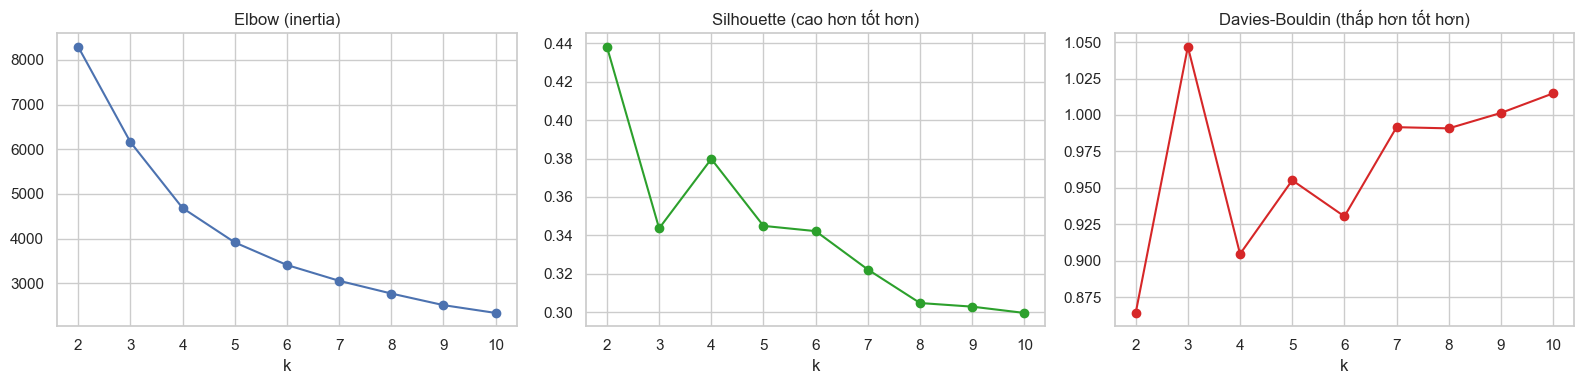

In [14]:

X = df_customers_scaled

K_RANGE = range(2, 11)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X, km.labels_, sample_size=5000, random_state=RANDOM_STATE),
        "davies_bouldin": davies_bouldin_score(X, km.labels_),
    })
k_eval = pd.DataFrame(rows)
display(k_eval.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(k_eval.k, k_eval.inertia, "o-"); axes[0].set_title("Elbow (inertia)")
axes[1].plot(k_eval.k, k_eval.silhouette, "o-", color="tab:green"); axes[1].set_title("Silhouette (cao hơn tốt hơn)")
axes[2].plot(k_eval.k, k_eval.davies_bouldin, "o-", color="tab:red"); axes[2].set_title("Davies-Bouldin (thấp hơn tốt hơn)")
for a in axes: a.set_xlabel("k")
plt.tight_layout(); plt.savefig("reports/k_selection.png", dpi=120); plt.show()

In [15]:

BEST_K = int(k_eval.loc[k_eval[k_eval.k.between(3, 6)].silhouette.idxmax(), "k"])
print("k được chọn:", BEST_K)

k được chọn: 4


## 6. Huấn luyện mô hình cuối và kiểm tra


In [16]:
kmeans = KMeans(n_clusters=BEST_K, n_init=20, random_state=RANDOM_STATE).fit(X)
rfm["Cluster"] = kmeans.labels_

print("Silhouette:", round(silhouette_score(X, kmeans.labels_, sample_size=5000, random_state=RANDOM_STATE), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X, kmeans.labels_), 3))

# Độ ổn định: so sánh với các seed khác bằng ARI
aris = [adjusted_rand_score(kmeans.labels_, KMeans(n_clusters=BEST_K, n_init=10, random_state=s).fit(X).labels_) for s in range(1, 6)]
print("ARI trung bình giữa các seed:", round(np.mean(aris), 3))

Silhouette: 0.38
Davies-Bouldin: 0.903
ARI trung bình giữa các seed: 0.975


In [17]:
rfm["Cluster"] = kmeans.labels_
rfm.head(5)


,Customer ID,Recency,Frequency,Monetary,Country,Cluster
0,12346,326,12,77556.46,United Kingdom,2
1,12347,2,8,4921.53,Iceland,2
2,12348,75,5,2019.40,Finland,3
3,12349,19,4,4428.69,Italy,2
4,12350,310,1,334.40,Norway,1


# 7. Trực quan hóa các cụm

In [18]:
rfm.groupby("Cluster").agg(
{
    'Recency':'mean',
    "Frequency":'mean',
    'Monetary':'mean'
}
)
    

,Recency,Frequency,Monetary
Cluster,,,
0,39.692557,2.393204,665.297340
1,430.571610,1.201521,283.855438
2,32.031231,15.615015,8358.233314
3,287.058613,4.371694,1564.056045


In [19]:
rfm.head()

,Customer ID,Recency,Frequency,Monetary,Country,Cluster
0,12346,326,12,77556.46,United Kingdom,2
1,12347,2,8,4921.53,Iceland,2
2,12348,75,5,2019.40,Finland,3
3,12349,19,4,4428.69,Italy,2
4,12350,310,1,334.40,Norway,1


## 8. Nạp dữ liệu thô vào PostgreSQL (schema `staging`)

**Vì sao làm vậy?**
- Dữ liệu được nạp nguyên bản vào `staging`, việc chia Star Schema (`dw`) sẽ làm bằng SQL sau đó.
- Hai bảng có độ chi tiết khác nhau: giao dịch (mỗi dòng là một dòng hóa đơn) và khách hàng (mỗi dòng là một khách, kèm RFM và cụm).
- Thông tin kết nối đọc từ file `.env`, không ghi mật khẩu trong notebook.
- Mỗi lần chạy thay thế bảng cũ nên không bị nhân đôi dữ liệu. Nhãn cụm 0/1/2/3 chỉ có nghĩa trong một lần train, nên train lại thì phải nạp lại.

In [20]:
# --- Nạp dữ liệu thô vào PostgreSQL (schema staging) ---
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

load_dotenv()
engine = create_engine(
    f"postgresql+psycopg2://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}"
)

# Thử kết nối
with engine.connect() as conn:
    print("Đã kết nối database:", conn.execute(text("select current_database()")).scalar())

# Bảng giao dịch: đặt tên cột snake_case, bỏ TotalPrice (sẽ tính bằng DAX)
transactions = data.rename(columns={
    "Invoice": "invoice_no", "StockCode": "stock_code", "Description": "description",
    "Quantity": "quantity", "InvoiceDate": "invoice_datetime", "Price": "unit_price",
    "Customer ID": "customer_id", "Country": "country",
})[["invoice_no", "stock_code", "description", "quantity",
    "invoice_datetime", "unit_price", "customer_id", "country"]].copy()
transactions["customer_id"] = transactions["customer_id"].astype("int64")

# Bảng khách hàng: RFM + cụm
customers = rfm.rename(columns={
    "Customer ID": "customer_id", "Recency": "recency", "Frequency": "frequency",
    "Monetary": "monetary", "Cluster": "cluster_id",
})[["customer_id", "recency", "frequency", "monetary", "cluster_id"]].copy()
customers["customer_id"] = customers["customer_id"].astype("int64")

# Ghi vào staging, thay thế bảng cũ mỗi lần chạy, nạp theo khối
transactions.to_sql("transactions_clean", engine, schema="staging",
                    if_exists="replace", index=False, chunksize=50_000, method="multi")
customers.to_sql("customer_rfm_clusters", engine, schema="staging",
                 if_exists="replace", index=False)

# Kiểm tra số dòng
with engine.connect() as conn:
    for t, n in [("transactions_clean", len(transactions)), ("customer_rfm_clusters", len(customers))]:
        print(t, "| DataFrame:", n, "| DB:", conn.execute(text(f"select count(*) from staging.{t}")).scalar())

Đã kết nối database: online_retail_dw
transactions_clean | DataFrame: 779425 | DB: 779425
customer_rfm_clusters | DataFrame: 5878 | DB: 5878
